# Dollarama Inc. (TSX: DOL) — 10-Year Ratio & Financial Analysis

**Author:** Munzeleen Sarwar · **Date:** October 2026 · **Currency:** CAD millions unless noted

This notebook supports the equity-research portfolio project in this repository. It loads
Dollarama's reported financials (data collected in `scripts/fetch_data.py` from StockAnalysis.com,
which traces to Dollarama's filed statements), computes profitability, efficiency, leverage and
shareholder-return ratios, and charts the story. The companion Excel model
(`Dollarama_Financial_Model.xlsx`) builds the forecast and DCF from the same data.

**Method notes**
- Fiscal years end late January / early February; FY2026 ended 1 February 2026.
- Dollarama reports under IFRS 16, so lease liabilities are financing. Leverage below includes leases.
- **ROE is deliberately not used**: buybacks have shrunk the equity base so far that book equity was
  *negative* in FY2022–FY2023. ROE of several hundred (or negative) percent is arithmetic, not insight.
  ROA and margins carry the analysis instead.

In [1]:
import json, re
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 9, "figure.dpi": 120})
NAVY, TEAL, GREY = "#1F3864", "#2E86AB", "#9AA5B1"

stmts = json.load(open("data/statements.json"))
inc, bal, cf = stmts["income"], stmts["balance"], stmts["cashflow"]
FYS = ["FY 2022", "FY 2023", "FY 2024", "FY 2025", "FY 2026"]
def g(d, k, p):
    v = d.get(k, {}).get(p)
    return None if v is None else float(v)
print("Loaded:", {k: len(v) for k, v in stmts.items()}, "statement lines")

Loaded: {'income': 39, 'balance': 53, 'cashflow': 45} statement lines


## 1 — A decade of growth, no down years
Revenue history comes from StockAnalysis.com's revenue history table (FY2009 onwards). Dollarama has grown revenue every year in the window — through COVID, an inflation shock and rising rates.

In [2]:
rh = pd.read_csv("data/revenue_history.csv")
def to_num(s):
    s = str(s).replace(",", "").strip()
    m = re.match(r"([\d.]+)\s*([BM])", s)
    if m: return float(m.group(1)) * (1000 if m.group(2) == "B" else 1)
    try: return float(s)
    except Exception: return None
rows = []
for _, r in rh.iterrows():
    year = int(re.search(r"(\d{4})", str(r.iloc[0])).group(1))
    rows.append({"FY": f"FY{year}", "Revenue": to_num(r.iloc[1])})
rev = pd.DataFrame(rows).sort_values("FY").tail(10).reset_index(drop=True)
rev["Growth %"] = rev["Revenue"].pct_change() * 100
cagr10 = (rev["Revenue"].iloc[-1] / rev["Revenue"].iloc[0]) ** (1/9) - 1
print(f"Revenue FY2017 {rev['Revenue'].iloc[0]:,.0f} -> FY2026 {rev['Revenue'].iloc[-1]:,.0f}; 10-year CAGR {cagr10:.1%}")
rev

Revenue FY2017 2,960 -> FY2026 7,260; 10-year CAGR 10.5%


,FY,Revenue,Growth %
0,FY2017,2960.0,NaN
1,FY2018,3270.0,10.472973
2,FY2019,3550.0,8.562691
3,FY2020,3790.0,6.760563
4,FY2021,4030.0,6.332454
5,FY2022,4330.0,7.444169
6,FY2023,5050.0,16.628176
7,FY2024,5870.0,16.237624
8,FY2025,6410.0,9.199319
9,FY2026,7260.0,13.260530


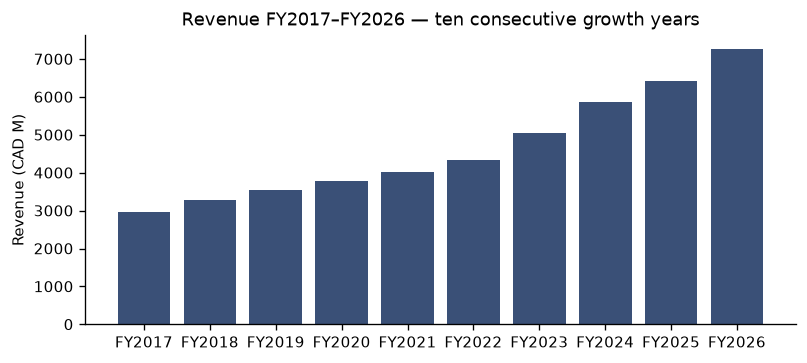

In [3]:
fig, ax = plt.subplots(figsize=(6.8, 3.1))
ax.bar(rev["FY"], rev["Revenue"], color=NAVY, alpha=.88)
ax.set_ylabel("Revenue (CAD M)")
ax.set_title("Revenue FY2017–FY2026 — ten consecutive growth years")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 2 — Profitability: high, stable margins
Gross margin sits in a tight 44.5–47.3% band and operating margin between 22.7% and 24.7%. For a retailer selling at price points capped at $5, that stability — passing through inflation in 2022–24 with only modest gross-margin compression — is the core quality signal.

In [4]:
rat = {}
for fy in FYS:
    r = g(inc, "Revenue", fy)
    rat[fy] = {
        "Gross margin %": g(inc, "Gross Profit", fy) / r * 100,
        "Operating margin %": g(inc, "Operating Income", fy) / r * 100,
        "Net margin %": g(inc, "Net Income", fy) / r * 100,
        "ROA %": g(inc, "Net Income", fy) / g(bal, "Total Assets", fy) * 100,
        "Current ratio": g(bal, "Total Current Assets", fy) / g(bal, "Total Current Liabilities", fy),
        "Inventory days": g(bal, "Inventory", fy) / g(inc, "Cost of Revenue", fy) * 365,
        "FCF margin %": g(cf, "Free Cash Flow", fy) / r * 100,
        "EPS diluted": g(inc, "EPS (Diluted)", fy),
    }
ratios = pd.DataFrame(rat).T.round(2)
ratios

,Gross margin %,Operating margin %,Net margin %,ROA %,Current ratio,Inventory days,FCF margin %,EPS diluted
FY 2022,47.31,22.79,15.31,16.32,0.79,94.52,23.60,2.18
FY 2023,46.53,22.68,15.87,16.64,0.99,129.30,14.55,2.76
FY 2024,44.54,24.20,17.21,19.19,1.93,102.84,21.78,3.56
FY 2025,45.13,24.65,18.23,18.03,1.18,95.54,22.31,4.16
FY 2026,45.05,24.06,18.04,17.32,1.13,100.98,20.84,4.73


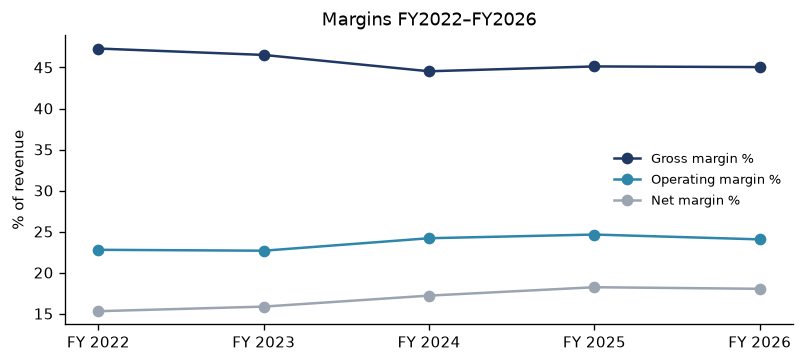

In [5]:
fig, ax = plt.subplots(figsize=(6.8, 3.1))
for col, c in [("Gross margin %", NAVY), ("Operating margin %", TEAL), ("Net margin %", GREY)]:
    ax.plot(ratios.index, ratios[col], marker="o", label=col, color=c)
ax.set_ylabel("% of revenue"); ax.set_title("Margins FY2022–FY2026")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3 — Cash conversion and shareholder returns
Free cash flow (operating cash flow less capex, *before* lease payments) tracks well above net income because depreciation is large and capex is light — stores are cheap to open. Management returns most of it: buybacks dwarf the small dividend (payout under 10%). Falling share count is why EPS compounds at ~21% a year while net income grows ~17%.

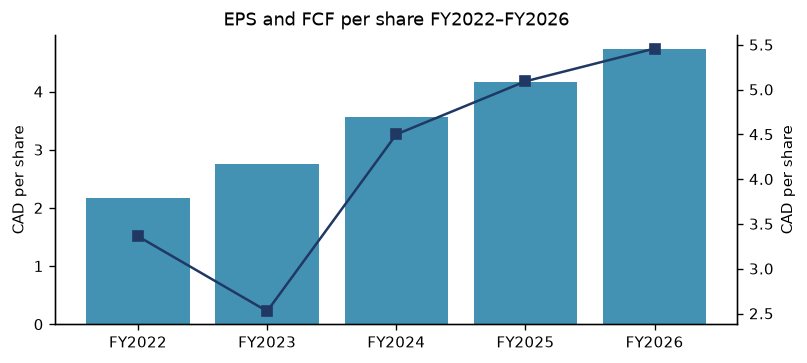

,Buybacks,Dividends,FCF,Returned % of FCF
FY 2022,1060.0,60.0,1022.0,110.0
FY 2023,689.0,63.0,735.0,102.0
FY 2024,656.0,76.0,1278.0,57.0
FY 2025,1091.0,97.0,1431.0,83.0
FY 2026,864.0,113.0,1512.0,65.0


In [6]:
fig, ax = plt.subplots(figsize=(6.8, 3.1))
fy5 = [f.replace("FY ", "FY") for f in FYS]
ax.bar(fy5, [g(inc, "EPS (Diluted)", f) for f in FYS], color=TEAL, alpha=.9, label="EPS diluted (CAD)")
ax2 = ax.twinx()
ax2.plot(fy5, [g(cf, "Free Cash Flow", f) / g(inc, "Shares Outstanding (Diluted)", f) for f in FYS],
         marker="s", color=NAVY, label="FCF per share (CAD)")
ax.set_ylabel("CAD per share"); ax2.set_ylabel("CAD per share")
ax.set_title("EPS and FCF per share FY2022–FY2026")
ax.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
plt.tight_layout(); plt.show()

returns = pd.DataFrame({fy: {"Buybacks": -g(cf, "Repurchase of Common Stock", fy),
                             "Dividends": -g(cf, "Common Dividends Paid", fy),
                             "FCF": g(cf, "Free Cash Flow", fy)} for fy in FYS}).T
returns["Returned % of FCF"] = (returns["Buybacks"] + returns["Dividends"]) / returns["FCF"] * 100
returns.round(0)

## 4 — Leverage, honestly stated
Total debt including leases was $5,396M at FY2026 against $340M of cash — net debt of about $5,056M, roughly 2.3x FY2026 EBIT plus total depreciation. That is comfortable for a retailer with this cash conversion, but it is not the near-zero leverage a debt-only glance would suggest: leases are real obligations.

In [7]:
lev = pd.DataFrame({fy: {"Total debt incl. leases": g(bal, "Total Debt", fy),
                           "Cash & ST investments": g(bal, "Cash & Short-Term Investments", fy),
                           "Net debt incl. leases": g(bal, "Total Debt", fy) - g(bal, "Cash & Short-Term Investments", fy),
                           "of which lease liabilities": (g(bal, "Long-Term Leases", fy) or 0) + (g(bal, "Current Portion of Leases", fy) or 0)}
                      for fy in FYS}).T.round(0)
lev

,Total debt incl. leases,Cash & ST investments,Net debt incl. leases,of which lease liabilities
FY 2022,3617.0,71.0,3546.0,1728.0
FY 2023,4219.0,101.0,4118.0,1961.0
FY 2024,4334.0,316.0,4018.0,2070.0
FY 2025,4710.0,135.0,4575.0,2427.0
FY 2026,5396.0,340.0,5056.0,2771.0


## 5 — Valuation context (detail in the report)
At $204.59 (21 October 2026) Dollarama trades on about 41x trailing earnings — roughly double the peer median — while also posting the group's best margins. Whether that premium is earned is the valuation question the DCF and comps in the Excel model take up.

In [8]:
peers = json.load(open("data/peers.json"))
want = ["PE Ratio", "Forward PE", "PS Ratio", "P/FCF Ratio", "Gross Margin", "Operating Margin", "Profit Margin", "Revenue Growth"]
comp = pd.DataFrame({n: {k: d.get(k, {}).get("TTM", d.get(k, {}).get("Current")) for k in want} for n, d in peers.items()}).T
comp.round(2)

,PE Ratio,Forward PE,PS Ratio,P/FCF Ratio,Gross Margin,Operating Margin,Profit Margin,Revenue Growth
Dollarama (TSX: DOL),41.05,38.28,6.96,33.80,0.45,0.23,0.17,0.18
Dollar General (NYSE: DG),17.15,16.53,0.67,14.50,0.31,0.06,0.04,0.05
Dollar Tree (NASDAQ: DLTR),15.39,18.24,1.17,11.90,0.37,0.09,0.08,0.08
Five Below (NASDAQ: FIVE),20.12,22.04,2.32,20.59,0.38,0.12,0.12,0.26
Loblaw (TSX: L),28.86,25.61,1.21,14.93,0.31,0.07,0.04,0.07
Metro (TSX: MRU),22.79,18.64,0.89,16.77,0.19,0.06,0.04,0.03
Couche-Tard (TSX: ATD),17.25,18.13,0.68,14.82,0.18,0.06,0.04,0.12


## Key takeaways
1. **Compounding machine**: 10-year revenue CAGR ≈ 10.5%, EPS CAGR (FY2022–26) ≈ 21%, powered by store growth, margin stability and buybacks.
2. **Margins are the moat**: ~45% gross / ~24% operating margins at $5-max price points is an unusual, durable combination in retail.
3. **Cash first**: FCF margin around 21–24% of revenue; capital returns are buyback-led, which also makes book-equity ratios (ROE) meaningless.
4. **Leases matter**: honest leverage is ~$5.1B net including leases — manageable, but it belongs in any valuation bridge.
5. **Price is the problem**: at ~41x earnings the market already pays for years of flawless execution; the DCF base case ($183) sits ~10% below the price. Quality: excellent. Entry price: demanding.